# 💘 RiskMatch — Step-by-Step Execution Pipeline

This notebook is the project's **reproducible runbook**. Each substep corresponds to a task in `CHECKLIST.md` and must be executed in order.

## Priority Order

1. Data and baselines
2. Fixed, transparent client profile mapped to a risk category
3. QARM engines: Markowitz, ERC, Black-Litterman, and prepared risk-band portfolios
4. StockTwits sentiment and out-of-sample validation
5. Walk-forward validation, category-strategy catalogue, and simplified application
6. Extensions only after the core has been validated: adaptive questionnaire, HMM regimes, FOMC, and Monte Carlo

Before completing a cell, read `docs/03_METHODOLOGY.md`. A cell is considered complete only when its result has been saved, verified, and covered by a test whenever the logic is reused in `src/`.

---
# Step 0 — Setup

In [ ]:
%pip install -r requirements.txt

### 0.1 — Imports

In [1]:
# pandas, numpy, scipy.optimize, matplotlib/plotly, yfinance, pandas_datareader, sklearn, hmmlearn, json, yaml
import sys, json, warnings, platform
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import scipy
from scipy import optimize, stats
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import yaml
from sklearn.covariance import LedoitWolf

OPTIONAL = {}
for name in ["yfinance", "pandas_datareader", "hmmlearn"]:
    try:
        OPTIONAL[name] = __import__(name)
    except ImportError:
        OPTIONAL[name] = None
        print(f"⚠️ {name} not installed — needed later (pip install -r requirements.txt)")

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scipy {scipy.__version__}")
for name, mod in OPTIONAL.items():
    print(f"{name}: {getattr(mod, '__version__', 'installed') if mod else 'MISSING'}")

Matplotlib is building the font cache; this may take a moment.


Python 3.12.16 | pandas 2.3.3 | numpy 2.5.5 | scipy 1.18.1
yfinance: 0.2.66
pandas_datareader: 0.11.1
hmmlearn: 0.3.3


### 0.2 — Configuration (tickers, dates, SEED, assumptions)

In [2]:
# Load config.yaml: tickers, dates, seed, costs, RISK_BANDS, client display metrics
with open(ROOT / "config.yaml", encoding="utf-8") as f:
    CFG = yaml.safe_load(f)

SEED = CFG["seed"]
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

SECTORS = CFG["tickers"]["sectors"]
DIVERSIFIERS = CFG["tickers"]["diversifiers"]
ASSETS = SECTORS + DIVERSIFIERS                  # investable universe (12 ETFs)
BENCH = CFG["benchmark"]                         # SPY
BENCH_60_40 = {BENCH: 0.60, "IEF": 0.40}
ALL_TICKERS = ASSETS + [BENCH]

START = CFG["start_date"]
CURRENCY = CFG["currency"]
SR_REF = CFG["reference_sharpe"]
COST_BPS_GRID = CFG["transaction_cost_bps"]
COST_BPS = CFG["validation"]["transaction_cost_bps_main"]
SIGMA_GRID = CFG["target_volatility_grid"]

PF = CFG["portfolio"]
REBAL = PF["rebalance_frequency"]
WINDOW_YEARS = PF["estimation_window_years"]
WINDOW_DAYS = 252 * WINDOW_YEARS
LONG_ONLY = PF["long_only"]
LEVERAGE_LIMIT = PF["leverage_limit"]
BORROW_SPREAD = PF.get("borrowing_spread_bps", 0) / 1e4
W_MAX = PF["max_weight_per_asset"]

PERIODS = CFG["validation"].get("periods", {})
BL_ANCHOR = CFG.get("black_litterman", {}).get("anchor", "erc")
SENTIMENT_END = CFG.get("sentiment", {}).get("coverage_end")
RF_SERIES = CFG["fred_series"]["risk_free"]
MACRO_SERIES = CFG["fred_series"]["macro"]
CORE_STRATEGIES = CFG["scope"]["core_strategies"]

# Sanity checks — fail early if the config is inconsistent
assert len(set(ALL_TICKERS)) == len(ALL_TICKERS), "duplicate tickers"
assert W_MAX * len(ASSETS) >= 1, "w_max too low: weights cannot sum to 1"
assert 1.0 <= LEVERAGE_LIMIT <= 1.5, "leverage limit outside the approved range (DR-03)"
assert all(0 < s < 0.5 for s in SIGMA_GRID), "target volatility grid looks wrong"

print(f"Universe ({len(ASSETS)}): {ASSETS} | benchmark: {BENCH_60_40}")
print(f"Start {START} | window {WINDOW_YEARS}y | rebal {REBAL} | costs {COST_BPS} bps (grid {COST_BPS_GRID})")
print(f"Leverage ≤ {LEVERAGE_LIMIT}x, borrowing spread {BORROW_SPREAD:.2%} | w_max {W_MAX:.0%} | long-only {LONG_ONLY}")
print(f"σ* grid: {SIGMA_GRID} | SR_ref {SR_REF} | BL anchor: {BL_ANCHOR} | sentiment until {SENTIMENT_END}")
for name, p in PERIODS.items():
    print(f"Backtest '{name}': {p['start']} → {p['end'] or 'latest'}")

Universe (12): ['XLK', 'XLF', 'XLE', 'XLV', 'XLY', 'XLP', 'XLI', 'XLB', 'XLU', 'IEF', 'TLT', 'GLD'] | benchmark: {'SPY': 0.6, 'IEF': 0.4}
Start 2006-01-01 | window 3y | rebal monthly | costs 10 bps (grid [0, 10, 25])
Leverage ≤ 1.5x, borrowing spread 1.00% | w_max 35% | long-only True
σ* grid: [0.05, 0.08, 0.1, 0.14] | SR_ref 0.35 | BL anchor: erc | sentiment until 2020-03-31
Backtest 'main': 2010-01-01 → 2020-03-31
Backtest 'extended': 2009-01-01 → latest


### 0.3 — Folder Paths (data/, results/, questions/)

In [3]:
# Path(...) + create if missing
from src.paths import DATA, RAW_DATA, PROCESSED_DATA, RESULTS, QUESTIONS

FIGURES = RESULTS / "figures"
for folder in [DATA, RAW_DATA, PROCESSED_DATA, RESULTS, FIGURES, QUESTIONS]:
    folder.mkdir(parents=True, exist_ok=True)

for label, folder in {"raw": RAW_DATA, "processed": PROCESSED_DATA, "results": RESULTS,
                      "figures": FIGURES, "questions": QUESTIONS}.items():
    n = len([p for p in folder.iterdir() if not p.name.startswith(".")])
    print(f"{label:<10} {folder.relative_to(ROOT)}  ({n} files)")

raw        data/raw  (0 files)
processed  data/processed  (0 files)
results    results  (2 files)
figures    results/figures  (0 files)
questions  questions  (2 files)


---
# Step 1 — Data Collection

### 1.1 — Adjusted ETF Prices (yfinance)

,first_date,last_date,n_obs,n_NaN,jumps_>25%
Ticker,,,,,
XLK,2006-01-03,2026-11-16,5251,0,0
XLF,2006-01-03,2026-11-16,5251,0,0
XLE,2006-01-03,2026-11-16,5251,0,0
XLV,2006-01-03,2026-11-16,5251,0,0
XLY,2006-01-03,2026-11-16,5251,0,0
XLP,2006-01-03,2026-11-16,5251,0,0
XLI,2006-01-03,2026-11-16,5251,0,0
XLB,2006-01-03,2026-11-16,5251,0,0
XLU,2006-01-03,2026-11-16,5251,0,0


/var/folders/lc/fgrlwls53d304sw4x6xjbkhh0000gn/T/ipykernel_51092/6038336.py:26: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  late = check[pd.to_datetime(check["first_date"]) > pd.Timestamp(START) + pd.Timedelta(days=10)]


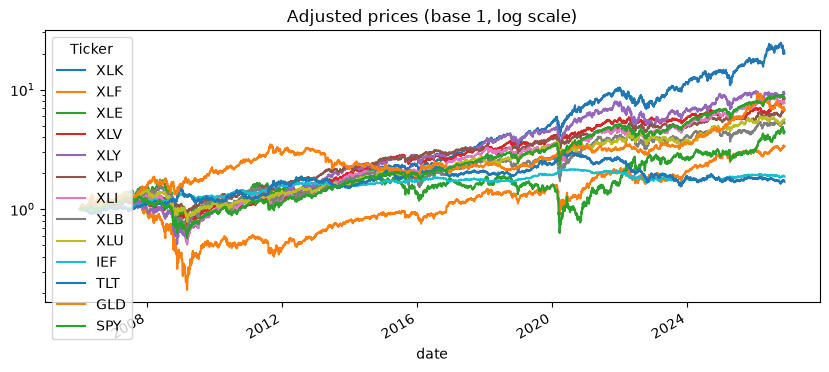

In [4]:
# XLK XLF XLE XLV XLY XLP XLI XLB XLU IEF TLT GLD + SPY
# 1.1 — Adjusted ETF prices (yfinance)
yf = OPTIONAL["yfinance"]
assert yf is not None, "yfinance missing: pip install -r requirements.txt"

raw = yf.download(ALL_TICKERS, start=START, auto_adjust=True,
                  progress=False, group_by="column")
prices_raw = raw["Close"][ALL_TICKERS]                 # adjusted close (dividends included)
prices_raw.index = pd.to_datetime(prices_raw.index).tz_localize(None)
prices_raw.index.name = "date"
prices_raw.to_csv(RAW_DATA / "etf_prices_adjusted.csv")  # raw copy, never modified

# --- Quality checks ---
daily_ret = prices_raw.pct_change(fill_method=None)
check = pd.DataFrame({
    "first_date": prices_raw.apply(lambda s: s.first_valid_index().date()),
    "last_date":  prices_raw.apply(lambda s: s.last_valid_index().date()),
    "n_obs":      prices_raw.notna().sum(),
    "n_NaN":      prices_raw.isna().sum(),
    "jumps_>25%": (daily_ret.abs() > 0.25).sum(),
})
display(check)

missing = [t for t in ALL_TICKERS if prices_raw[t].isna().all()]
assert not missing, f"no data downloaded for: {missing}"
late = check[pd.to_datetime(check["first_date"]) > pd.Timestamp(START) + pd.Timedelta(days=10)]
if not late.empty:
    print("⚠️ tickers starting after START:", list(late.index))

(prices_raw / prices_raw.bfill().iloc[0]).plot(logy=True, figsize=(10, 4),
    title="Adjusted prices (base 1, log scale)");

### 1.2 — DTB3 Risk-Free Rate (FRED) → Daily Rate

DTB3: 2006-01-02 → 2026-11-13 | 224 NaN (holidays, filled in step 1.6)


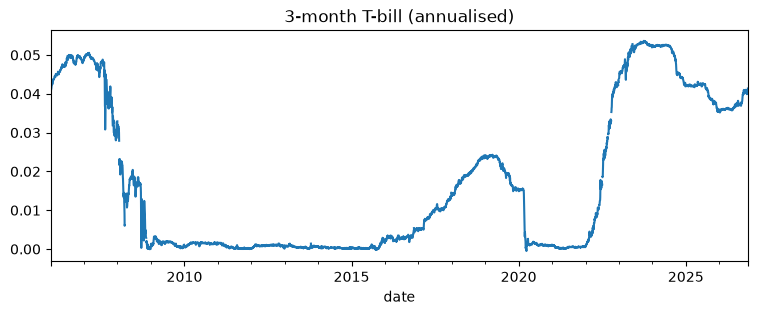

In [5]:
# 1.2 — Risk-free rate DTB3 (FRED) → daily rate
url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={RF_SERIES}"
rf_raw = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
rf_raw.index.name = "date"
rf_raw.to_csv(RAW_DATA / f"{RF_SERIES}.csv")          # raw copy, never modified

rf_annual = rf_raw[RF_SERIES].loc[START:] / 100       # % → decimal (annualised)
rf_daily = (rf_annual / 252).rename("rf_daily")       # daily rate, as in the README

print(f"{RF_SERIES}: {rf_annual.index.min().date()} → {rf_annual.index.max().date()} | "
      f"{rf_annual.isna().sum()} NaN (holidays, filled in step 1.6)")
rf_annual.plot(title="3-month T-bill (annualised)", figsize=(9, 3));

### 1.3 — FRED Macroeconomic Variables (T10Y2Y, BAA10Y, VIXCLS, CPIAUCSL, UNRATE, INDPRO)

In [6]:
# 1.3 — FRED macro variables (extension: HMM regimes)
TRANSFORM = {               # README §1.3
    "T10Y2Y":   "level",    # yield-curve slope (daily)
    "BAA10Y":   "level",    # credit spread (daily)
    "VIXCLS":   "log",      # VIX (daily)
    "CPIAUCSL": "yoy",      # inflation (monthly)
    "UNRATE":   "diff12",   # unemployment (monthly)
    "INDPRO":   "yoy",      # industrial production (monthly)
}
assert set(TRANSFORM) == set(MACRO_SERIES), "TRANSFORM must match config.yaml"

macro_raw = {}
for sid in MACRO_SERIES:
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"
    s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s.index.name = "date"
    s.to_frame(sid).to_csv(RAW_DATA / f"{sid}.csv")      # raw copy
    macro_raw[sid] = s.dropna()

def transform(s, how):
    if how == "level":  return s
    if how == "log":    return np.log(s)
    if how == "yoy":    return s.pct_change(12, fill_method=None)   # 12-month % change
    if how == "diff12": return s.diff(12)                           # 12-month change in points
    raise ValueError(how)

# Transformations are computed on the OBSERVATION dates (before any lag)
macro_obs = {sid: transform(s, TRANSFORM[sid]).dropna() for sid, s in macro_raw.items()}

summary = pd.DataFrame({
    sid: {"frequency": pd.infer_freq(s.index[-50:]) or "daily/irregular",
          "first": s.index.min().date(), "last": s.index.max().date(),
          "n_obs": len(s), "transform": TRANSFORM[sid]}
    for sid, s in macro_obs.items()}).T
display(summary)

,frequency,first,last,n_obs,transform
T10Y2Y,daily/irregular,1976-06-01,2026-11-16,12611,level
BAA10Y,daily/irregular,1986-01-02,2026-11-13,10217,level
VIXCLS,B,1990-01-02,2026-11-13,9317,log
CPIAUCSL,daily/irregular,1948-01-01,2026-10-01,945,yoy
UNRATE,daily/irregular,1949-01-01,2026-10-01,933,diff12
INDPRO,MS,1920-01-01,2026-09-01,1281,yoy


### 1.3b — Publication Lag for Monthly Series

In [7]:
# 1.3b — Publication lag: index each series by the date it was AVAILABLE
MONTHLY = ["CPIAUCSL", "UNRATE", "INDPRO"]
macro_avail = {}
for sid, s in macro_obs.items():
    s = s.copy()
    if sid in MONTHLY:
        # FRED dates monthly data on the 1st of the month observed (e.g. Jan → 2024-01-01),
        # but it is only published the following month. Conservative rule:
        # available at the END of the following month.
        s.index = s.index + pd.offsets.MonthEnd(2)
    else:
        # Daily series: known at the close → usable from the next business day
        s.index = s.index + pd.offsets.BDay(1)
    s.index.name = "available_date"
    macro_avail[sid] = s

macro = pd.DataFrame(macro_avail)          # still irregular: aligned and ffilled in 1.6

# Check: January 2024 CPI must not be usable before end of February 2024
jan_cpi = macro_obs["CPIAUCSL"].loc["2024-01-01"]
first_use = macro["CPIAUCSL"][macro["CPIAUCSL"] == jan_cpi].index.min()
print(f"Jan-2024 CPI observed 2024-01-01 → first usable {first_use.date()}")
assert first_use >= pd.Timestamp("2024-02-01"), "look-ahead: monthly data used too early"

Jan-2024 CPI observed 2024-01-01 → first usable 2024-02-29


### 1.4 — Load StockTwits Data (Instructor-Provided File)

In [8]:
# 1.4 — StockTwits sentiment (Moodle / LN7 file)
ST_FILE = RAW_DATA / "sentratio_and_price_closetoclose_adj2.pkl"
assert ST_FILE.exists(), f"Put the Moodle file in {RAW_DATA}"

st_raw = pd.read_pickle(ST_FILE)
KEEP = ["date", "ticker", "Nbullish", "Nbearish", "N", "Polarity", "total_vol_tweet"]
st = st_raw[[c for c in KEEP if c in st_raw.columns]].copy()
st["date"] = pd.to_datetime(st["date"], utc=True).dt.tz_localize(None).dt.normalize()
st = st.drop_duplicates(["date", "ticker"]).sort_values(["ticker", "date"]).reset_index(drop=True)

# Sentiment of day t is known only after the close → usable from t+1 (anti look-ahead)
st["available_date"] = st["date"] + pd.offsets.BDay(1)

cov = st.groupby("ticker").agg(first=("date", "min"), last=("date", "max"),
                               days=("date", "nunique"), msgs=("N", "sum"),
                               median_N=("N", "median"), mean_polarity=("Polarity", "mean"))
display(cov.sort_values("msgs", ascending=False))
print(f"{st['ticker'].nunique()} tickers | {st['date'].min().date()} → {st['date'].max().date()} | {len(st):,} rows")

,first,last,days,msgs,median_N,mean_polarity
ticker,,,,,,
SPY,2010-01-04,2020-03-23,2564,5139795.0000,1217.5000,0.4000
AAPL,2010-01-04,2020-03-23,2564,2738929.0000,858.0000,0.6121
TSLA,2010-01-04,2020-03-23,2564,1757434.0000,325.0000,0.3845
AMD,2010-01-04,2020-03-23,2564,1578389.0000,86.0000,0.5079
FB,2010-01-04,2020-03-23,2564,1025951.0000,283.5000,0.4905
AMZN,2010-01-04,2020-03-23,2564,902651.0000,142.5000,0.4931
BB,2010-01-04,2020-03-23,2564,898221.0000,250.0000,0.6370
NFLX,2010-01-04,2020-03-23,2564,724987.0000,171.0000,0.3838
JNUG,2010-01-04,2020-03-23,2564,668873.0000,83.0000,0.3520


19 tickers | 2010-01-04 → 2020-03-23 | 48,716 rows


### 1.4b — Company-to-GICS-Sector Mapping

In [9]:
# 1.4b — Ticker → universe asset mapping (GICS sector)
TICKER_MAP = {
    "AAPL": ("XLK", "sector"),  "AMD":  ("XLK", "sector"),  "BB":   ("XLK", "sector"),
    "FB":   ("XLK", "sector"),  "TWTR": ("XLK", "sector"),   # IT sector before the 2018 GICS reform
    "AMZN": ("XLY", "sector"),  "TSLA": ("XLY", "sector"),  "NFLX": ("XLY", "sector"),
    "BABA": ("XLY", "sector"),
    "BAC":  ("XLF", "sector"),
    "AMRN": ("XLV", "sector"),  "MNKD": ("XLV", "sector"),   # small biotechs
    "PLUG": ("XLI", "sector"),
    "GLD":  ("GLD", "direct"),  "JNUG": ("GLD", "proxy"),    # JNUG = 3x junior gold miners
    "SPY":  ("MARKET", "market"), "QQQ": ("MARKET", "market"), "IWM": ("MARKET", "market"),
    "UVXY": (None, "excluded"),                              # VIX product, no asset
}
mapping = (pd.DataFrame.from_dict(TICKER_MAP, orient="index", columns=["asset", "role"])
             .rename_axis("ticker").reset_index())
unmapped = set(st["ticker"]) - set(mapping["ticker"])
assert not unmapped, f"tickers without mapping: {unmapped}"
mapping.to_csv(PROCESSED_DATA / "stocktwits_ticker_mapping.csv", index=False)

st = st.merge(mapping, on="ticker", how="left")
coverage = (pd.Series({a: sorted(st.loc[st["asset"] == a, "ticker"].unique()) for a in ASSETS + ["MARKET"]})
              .rename("tickers").to_frame())
coverage["n_tickers"] = coverage["tickers"].str.len()
coverage["msgs"] = [st.loc[st["asset"] == a, "N"].sum() for a in coverage.index]
coverage["view_possible"] = coverage["n_tickers"] > 0
display(coverage)
print("Assets WITHOUT any sentiment:", list(coverage.index[~coverage["view_possible"]]))

,tickers,n_tickers,msgs,view_possible
XLK,"[AAPL, AMD, BB, FB, TWTR]",5,6876987.0000,True
XLF,[BAC],1,253738.0000,True
XLE,[],0,0.0000,False
XLV,"[AMRN, MNKD]",2,1033655.0000,True
XLY,"[AMZN, BABA, NFLX, TSLA]",4,3919812.0000,True
XLP,[],0,0.0000,False
XLI,[PLUG],1,474850.0000,True
XLB,[],0,0.0000,False
XLU,[],0,0.0000,False
IEF,[],0,0.0000,False


Assets WITHOUT any sentiment: ['XLE', 'XLP', 'XLB', 'XLU', 'IEF', 'TLT']


### 1.5 — FOMC Texts and Publication Dates

In [12]:
# 1.5 — FOMC statements: texts + publication dates (EXTENSION)
import re, time, requests
from bs4 import BeautifulSoup

FED = "https://www.federalreserve.gov"
HEADERS = {"User-Agent": "Mozilla/5.0 (academic project RiskMatch, HEC Lausanne)"}
FOMC_FILE = RAW_DATA / "fomc_statements.csv"
STATEMENT_RE = re.compile(r"monetary/?(\d{8})a\.htm")

def get_html(url, pause=1.0):
    r = requests.get(url, headers=HEADERS, timeout=30)
    r.raise_for_status()
    r.encoding = "utf-8" 
    time.sleep(pause)                      # be polite with the Fed's server
    return r.text

def statement_links(html):
    """{date: absolute url} for every statement link found on a calendar page."""
    out = {}
    for a in BeautifulSoup(html, "html.parser").find_all("a", href=True):
        m = STATEMENT_RE.search(a["href"])
        if m:                               # "…a.htm" = statement (minutes/notes use other names)
            out[pd.Timestamp(m.group(1))] = requests.compat.urljoin(FED, a["href"])
    return out

def statement_text(html):
    soup = BeautifulSoup(html, "html.parser")
    body = soup.find(id="article") or soup.find("div", class_=re.compile("col-md-8")) or soup
    paras = [p.get_text(" ", strip=True) for p in body.find_all("p")]
    paras = [p for p in paras if len(p) > 60 and "For media inquiries" not in p]
    return "\n".join(paras)

if FOMC_FILE.exists():
    fomc = pd.read_csv(FOMC_FILE, parse_dates=["date", "available_date"])
    print(f"Loaded from cache: {len(fomc)} statements")
else:
    first_year = pd.Timestamp(START).year
    pages = [f"{FED}/monetarypolicy/fomccalendars.htm"]                       # last ~5 years
    pages += [f"{FED}/monetarypolicy/fomchistorical{y}.htm"                   # older years
              for y in range(first_year, pd.Timestamp.today().year)]          # 404 for recent years = normal
    links = {}
    for url in pages:
        try:
            links.update(statement_links(get_html(url)))
        except requests.HTTPError:
            pass                                                              # page not archived yet
    links = {d: u for d, u in sorted(links.items()) if d >= pd.Timestamp(START)}
    print(f"{len(links)} statement links found — downloading texts (~{len(links)} s)…")

    rows = []
    for d, url in links.items():
        try:
            rows.append({"date": d, "url": url, "text": statement_text(get_html(url))})
        except requests.HTTPError as e:
            print(f"⚠️ {d.date()}: {e}")
    fomc = pd.DataFrame(rows)
    # Released at 2 pm ET, before the close; conservative rule: usable from the next business day
    fomc["available_date"] = fomc["date"] + pd.offsets.BDay(1)
    fomc["n_words"] = fomc["text"].str.split().str.len()
    fomc.to_csv(FOMC_FILE, index=False)

print(f"{len(fomc)} statements | {fomc['date'].min().date()} → {fomc['date'].max().date()}")
print("Statements per year:", fomc["date"].dt.year.value_counts().sort_index().to_dict())
short = fomc[fomc["n_words"] < 100]
if len(short):
    print("⚠️ suspiciously short texts (check parsing):", list(short["date"].dt.date))
display(fomc[["date", "available_date", "n_words", "url"]].tail())
print("\nLatest statement (start):\n", fomc["text"].iloc[-1][:400], "…")

176 statement links found — downloading texts (~176 s)…
176 statements | 2006-01-31 → 2026-10-28
Statements per year: {2006: 8, 2007: 9, 2008: 9, 2009: 8, 2010: 9, 2011: 8, 2012: 8, 2013: 8, 2014: 8, 2015: 8, 2016: 8, 2017: 8, 2018: 8, 2019: 9, 2020: 12, 2021: 8, 2022: 8, 2023: 8, 2024: 8, 2025: 9, 2026: 7}
⚠️ suspiciously short texts (check parsing): [datetime.date(2007, 8, 10)]


,date,available_date,n_words,url
171,2026-04-29,2026-04-30,341,https://www.federalreserve.gov/newsevents/pres...
172,2026-06-17,2026-06-18,131,https://www.federalreserve.gov/newsevents/pres...
173,2026-07-29,2026-07-30,167,https://www.federalreserve.gov/newsevents/pres...
174,2026-09-16,2026-09-17,131,https://www.federalreserve.gov/newsevents/pres...
175,2026-10-28,2026-10-29,173,https://www.federalreserve.gov/newsevents/pres...



Latest statement (start):
 The Federal Open Market Committee approved the following statement for release by a 10 – 2 vote:
The Committee decided to maintain the target range for the federal funds rate at 3-3/4 to 4 percent, in support of the Federal Reserve's dual mandate. The Committee is continuing its policy of maintaining ample reserves in the banking system.
Economic activity is expanding at a strong pace. While uncer …


### 1.6 — Cleaning and Alignment (Business Days, NaNs, Duplicates, Outliers)

In [13]:
# 1.6 — Cleaning and alignment
prices = prices_raw.loc[START:, ALL_TICKERS].sort_index()
prices = prices[~prices.index.duplicated(keep="first")]

# Common calendar = NYSE trading days on which ALL ETFs have a price (prices are NEVER filled)
complete = prices.notna().all(axis=1)
dropped = prices.index[~complete]
prices = prices[complete]
cal = prices.index
print(f"Calendar: {cal[0].date()} → {cal[-1].date()} | {len(cal):,} trading days | "
      f"{len(dropped)} incomplete days dropped {list(dropped.date[:5])}")

returns = prices.pct_change(fill_method=None).iloc[1:]      # simple returns (portfolios)
log_returns = np.log(prices).diff().iloc[1:]                # log returns (statistics only)

outliers = returns.stack()[returns.stack().abs() > 0.25]
print("Daily moves > 25% (check manually, NOT removed):", outliers.to_dict() if len(outliers) else "none")

# Risk-free: daily rate, holidays filled with the last published value
rf_d = (rf_raw[RF_SERIES] / 100 / 252).rename("rf_daily").sort_index()
rf_d = rf_d.reindex(rf_d.index.union(cal)).ffill().reindex(returns.index)
assert rf_d.notna().all(), "risk-free rate missing at the start of the sample"
excess_returns = returns.sub(rf_d, axis=0)

# Macro (extension): already indexed by availability date in 1.3b → ffill is safe
try:
    macro_d = (macro.sort_index().reindex(macro.index.union(cal)).ffill()
                    .reindex(returns.index))
    print(f"Macro aligned: {macro_d.shape[1]} series, first complete date "
          f"{macro_d.dropna().index.min().date()}")
except NameError:
    macro_d = None
    print("Macro not loaded (extension) — skipped")

# Sentiment: kept in long format, UVXY removed; aggregation happens in Step 4
try:
    st_clean = st[st["role"] != "excluded"].copy()
    print(f"Sentiment: {len(st_clean):,} rows, {st_clean['ticker'].nunique()} tickers kept")
except NameError:
    st_clean = None
    print("StockTwits not loaded — skipped")

# FOMC (extension): each statement mapped to the first trading day it can be used
try:
    fomc_clean = fomc.copy()
    pos = cal.searchsorted(fomc_clean["available_date"])           # next trading day on/after
    fomc_clean["trade_date"] = [cal[i] if i < len(cal) else pd.NaT for i in pos]
    fomc_clean = fomc_clean.dropna(subset=["trade_date"])
    print(f"FOMC: {len(fomc_clean)} statements mapped to trading days")
except NameError:
    fomc_clean = None
    print("FOMC not loaded (extension) — skipped")

# Final checks
assert returns.index.is_monotonic_increasing and not returns.index.duplicated().any()
assert returns.notna().all().all(), "NaN left in returns"
assert (prices > 0).all().all()
ann = pd.DataFrame({"ann_return": returns.mean() * 252, "ann_vol": returns.std() * np.sqrt(252),
                    "sharpe": excess_returns.mean() / returns.std() * np.sqrt(252)})
display(ann.round(3))

Calendar: 2006-01-03 → 2026-11-16 | 5,251 trading days | 0 incomplete days dropped []
Daily moves > 25% (check manually, NOT removed): none
Macro aligned: 6 series, first complete date 2006-01-04
Sentiment: 46,152 rows, 18 tickers kept
FOMC: 176 statements mapped to trading days


,ann_return,ann_vol,sharpe
Ticker,,,
XLK,0.1710,0.2310,0.6640
XLF,0.1010,0.2930,0.2860
XLE,0.1160,0.2990,0.3310
XLV,0.1160,0.1690,0.5850
XLY,0.1320,0.2220,0.5140
XLP,0.1030,0.1440,0.5930
XLI,0.1210,0.2110,0.4900
XLB,0.1070,0.2340,0.3830
XLU,0.1000,0.1870,0.4440


### 1.7 — Save to data/processed/*.parquet

In [14]:
# 1.7 — Save to data/processed/
import hashlib, datetime as dt

def save(df, name):
    path = PROCESSED_DATA / f"{name}.parquet"
    try:
        df.to_parquet(path)
    except ImportError:                      # pyarrow missing → CSV fallback
        path = path.with_suffix(".csv"); df.to_csv(path)
    return path

outputs = {"prices": prices, "returns": returns, "log_returns": log_returns,
           "excess_returns": excess_returns, "rf_daily": rf_d.to_frame()}
if macro_d is not None: outputs["macro"] = macro_d
if st_clean is not None: outputs["stocktwits"] = st_clean
if fomc_clean is not None: outputs["fomc"] = fomc_clean

meta = {"created": dt.datetime.now().isoformat(timespec="seconds"),
        "start": str(returns.index[0].date()), "end": str(returns.index[-1].date()),
        "tickers": ALL_TICKERS, "files": {}}
for name, df in outputs.items():
    path = save(df, name)
    meta["files"][name] = {"file": path.name, "shape": list(df.shape),
                           "md5": hashlib.md5(path.read_bytes()).hexdigest()}
    print(f"✓ {path.relative_to(ROOT)}  {df.shape}")

meta["sources"] = {"prices": "Yahoo Finance (yfinance, auto_adjust=True)",
                   "rf": f"FRED {RF_SERIES}",
                   "macro": "FRED " + ", ".join(MACRO_SERIES),
                   "stocktwits": "Course file sentratio_and_price_closetoclose_adj2.pkl (LN7)",
                   "fomc": "federalreserve.gov — FOMC statements (calendar + historical pages)"}
meta["availability_rules"] = {"prices": "close of day t",
                              "rf": "daily, holidays filled with last published value",
                              "macro_daily": "t + 1 business day",
                              "macro_monthly": "end of the month following the observation",
                              "stocktwits": "t + 1 business day",
                              "fomc": "t + 1 business day, mapped to next trading day"}
(PROCESSED_DATA / "metadata.json").write_text(json.dumps(meta, indent=2))
print("✓ metadata.json")

✓ data/processed/prices.parquet  (5251, 13)
✓ data/processed/returns.parquet  (5250, 13)
✓ data/processed/log_returns.parquet  (5250, 13)
✓ data/processed/excess_returns.parquet  (5250, 13)
✓ data/processed/rf_daily.parquet  (5250, 1)
✓ data/processed/macro.parquet  (5250, 6)
✓ data/processed/stocktwits.parquet  (46152, 10)
✓ data/processed/fomc.parquet  (176, 6)
✓ metadata.json


---
# Step 2 — Exploration and Estimation

### 2.1 — Descriptive Statistics by Asset

### 2.1b — Correlations: Heatmap and Rolling Equity/Bond Correlation

### 2.2 — Three-Year Rolling Σ: Sample vs. Ledoit-Wolf

### 2.2b — Instability Demonstration (Composition Maps)

### 2.3 — Conservative μ Estimator

### 2.4 — Reference Sharpe Ratio SR_T and Sensitivity

---
# Step 3 — Adaptive Questionnaire ⭐

### 3.1a — Block A — 10 Financial Capacity Questions

### 3.1b — Block B — 20 Risk Tolerance Questions (Ordered Scales)

### 3.1c — Block C — Generate 24 Swipe Pairs (φ_threshold on Log Grid [0.5, 20])

In [ ]:
# phi_seuil = 2*(mu_B - mu_A) / (sigma_B**2 - sigma_A**2)

### 3.1d — Block D — 6 Constraint Questions and Conditions

### 3.1e — Export questions/bank.json

### 3.2a — Swipe Likelihood (Logit Based on ΔU, λ)

### 3.2b — Ordered-Scale Likelihood (Graded Response)

### 3.2c — Prior Parameters for Block B Items

### 3.3 — Bayesian Engine on a θ = log φ Grid (Prior, Update, Estimators, SD, 80% CI)

### 3.4 — Adaptive Selection (Minimum Expected Posterior Variance) and Quotas

### 3.5 — Stopping Rule

### 3.6 — Mirrored Question and Inconsistency Detection

### 3.7 — Financial Capacity → σ*_cap

### 3.8 — φ → σ*_tol = SR_T/φ ; σ* = min(σ*_tol, σ*_cap)

### 3.8b — Map the Capped Estimate to a Risk Band and Test Every Boundary

In [ ]:
# Produce risk_band, risk_band_range, and reference_volatility.
# Verify that capacity overrides higher tolerance and that boundaries are deterministic.

### 3.9a — Synthetic Client Simulator

### 3.9b — Comparison: Adaptive / Random / Fixed / All 60 Questions

### 3.9c — Figure: Error vs. Number of Questions

### 3.9d — Robustness (Noise, Misspecified Parameters)

### 3.10 — Optional: Calibration Using a Real-World Survey

### 3.11 — Profile Object (JSON) — Example Output

---
# Step 4 — Signals

### 4.1 — Monthly Sector Sentiment and Abnormal Sentiment

### 4.2 — FOMC Tone (Offline Classification)

### 4.3a — View Matrix P

### 4.3b — Q Estimated from Historical Data

### 4.3c — Ω (Volume × Confidence)

### 4.4a — HMM: Select the Number of States (BIC)

### 4.4b — HMM with an Expanding Window → Filtered Probabilities

### 4.4c — Regime Description and Visualization

---
# Step 5 — Portfolio Construction

### 5.0 — Shared Functions and Quick Tests (Euler, ERC, BL Without Views)

### 5.1 — 🏛️ The Classic

### 5.2 — ⚖️ The Balanced (ERC)

### 5.3 — 🧠 The Connected (Black-Litterman and τ Calibration)

### 5.4 — 🌦️ The Chameleon (Regime-Based Budgets)

### 5.5 — 📈 The 60/40 Benchmark

### 5.6a — Tobin Allocation Toward Each Risk-Band Reference and Leverage Rule

In [ ]:
# Build one prepared allocation per validated strategy and risk-band reference.

### 5.6b — Reoptimization Under Client Constraints

### 5.7 — Portfolio Analytics (Weights, RC/RC*, Volatility, TE, IR, Concentration)

---
# Step 6 — Backtest

### 6.1 — Monthly Backtest Engine

### 6.2 — Four Risk-Band References × Active Strategies

In [ ]:
# Conservative 5%, Balanced 8%, Growth 10%, Aggressive 14%.
# Use the same comparison period and assumptions for every active strategy.

### 6.3 — Transaction Costs

### 6.4 — Scientific Metrics and Five Simplified Client Measures

In [ ]:
# Client cards: historical net annualized return, realized volatility, net Sharpe,
# maximum drawdown, and annualized cost.
# Technical panel: Sortino, Calmar, ES, turnover, concentration, TE, IR, RC, subperiods.

### 6.5 — Robustness

### 6.6 — Export Backtests, Metrics, Weights, and the Prepared Portfolio Catalogue

In [ ]:
# Export one dated and versioned row per risk_band × strategy.
# Include common period, net-of-cost metrics, and evidence-based pros/cons.

---
# Step 7 — Selection and Monitoring

### 7.1 — Record Category, Strategy, Catalogue Version, Shown Evidence, and Initial Position

### 7.2 — Monte Carlo Projection and Probability of Reaching the Goal

### 7.3 — Monitoring Since Selection (Separate from Frozen Historical Evidence)

### 7.4 — Rebalancing Rules and Alerts

### 7.5 — Brief Reprofiling

### 7.6 — Client Report

### 7.7 — Export / import JSON

---
# Step 8 — Export for the Web App

### 8.0 — Verify That All Files Read by the App Exist and Are Up to Date

### 8.6 — End-to-End Test: 20 Simulated Profiles Through the Entire Pipeline